#### Our First LangGraph

hello world

Step 1 — Install LangGraph

In [7]:

%pip install langgraph

  Using cached langgraph-1.2.20-py3-none-any.whl.metadata (4.9 kB)
  Using cached langchain_core-1.7.6-py3-none-any.whl.metadata (4.8 kB)
  Using cached langgraph_checkpoint-4.3.1-py3-none-any.whl.metadata (6.7 kB)
  Using cached langgraph_prebuilt-1.1.1-py3-none-any.whl.metadata (6.9 kB)
  Using cached langgraph_sdk-0.4.13-py3-none-any.whl.metadata (5.1 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
  Using cached langchain_protocol-0.0.20-py3-none-any.whl.metadata (2.4 kB)
  Using cached langsmith-0.14.17-py3-none-any.whl.metadata (39 kB)
  Using cached uuid_utils-1.2.0-cp310-abi3-win_amd64.whl.metadata (6.5 kB)
  Using cached httpx2-2.16.0-py3-none-any.whl.metadata (10 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached uuid_utils-0.19.0-cp310-abi3-win_amd64.whl.metadata (6.5 kB)
  Using cached httpcore2-2.16.0-py3-none-any.whl.metadata (27 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
Using cached

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [8]:
import importlib.metadata

print(importlib.metadata.version("langgraph"))

1.2.20


Step 2 — Create the State

State is simply the information travelling through our graph.

In [9]:
from typing import TypedDict

class State(TypedDict):
    message: str

Step 3 — Create our first node

A node is just a Python function.


In [10]:

def say_hello(state):
    state["message"] = "Hello"
    return state

Step 4 — Create another node

In [11]:

def add_name(state):
    state["message"] += " Everyone!"
    return state

Step 5 — Create the Graph

Now we use StateGraph.

In [12]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(State)

Step 6 — Add Nodes

In [13]:
builder.add_node("say_hello", say_hello)
builder.add_node("add_name", add_name)

Step 7 — Add Edges

Connect them:

In [14]:
builder.add_edge(START, "say_hello")
builder.add_edge("say_hello", "add_name")
builder.add_edge("add_name", END)

Step 8 — Compile the Graph

In [15]:
graph = builder.compile()

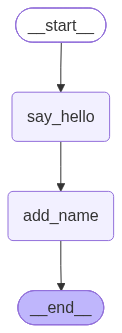

In [16]:
from IPython.display import Image

Image(graph.get_graph().draw_mermaid_png())

Step 9 — Run the Graph

In [17]:
result = graph.invoke({"message": ""})

print(result)

{'message': 'Hello Everyone!'}
